## Cell 1 – Import libraries and connect database

In [1]:

import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

# Connect to Airtel database
con = sqlite3.connect("../data/raw/airtel.db")

# SQL query helper function
def q(sql):
    return pd.read_sql_query(sql, con)

print("Database connected successfully!")


Database connected successfully!


In [2]:

tables = q("""
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name
""")

display(tables)


,name
0,circles
1,complaints
2,customer_features
3,customers
4,plans
5,recharges
6,usage_daily


Cell 3 – Inspect customer_features

In [3]:

customer_schema = q("PRAGMA table_info(customer_features)")
display(customer_schema)


,cid,name,type,notnull,dflt_value,pk
0,0,customer_id,INT,0,None,0
1,1,activation_date,TEXT,0,None,0
2,2,tenure_days,INT,0,None,0
3,3,tenure_years,INT,0,None,0
4,4,observed_days,INT,0,None,0
5,5,circle_name,TEXT,0,None,0
6,6,region,TEXT,0,None,0
7,7,plan_name,TEXT,0,None,0
8,8,plan_type,TEXT,0,None,0
9,9,price_inr,INT,0,None,0


Cell 4 – Inspect recharges

In [4]:

recharge_schema = q("PRAGMA table_info(recharges)")
display(recharge_schema)


,cid,name,type,notnull,dflt_value,pk
0,0,recharge_id,INTEGER,0,None,0
1,1,customer_id,INTEGER,0,None,0
2,2,recharge_date,TEXT,0,None,0
3,3,amount_inr,INTEGER,0,None,0
4,4,plan_id,INTEGER,0,None,0
5,5,channel,TEXT,0,None,0
6,6,txn_type,TEXT,0,None,0


In [5]:

print("CUSTOMER FEATURES COLUMNS")
display(customer_schema[['name', 'type']])

print("RECHARGES COLUMNS")
display(recharge_schema[['name', 'type']])


CUSTOMER FEATURES COLUMNS


,name,type
0,customer_id,INT
1,activation_date,TEXT
2,tenure_days,INT
3,tenure_years,INT
4,observed_days,INT
5,circle_name,TEXT
6,region,TEXT
7,plan_name,TEXT
8,plan_type,TEXT
9,price_inr,INT


RECHARGES COLUMNS


,name,type
0,recharge_id,INTEGER
1,customer_id,INTEGER
2,recharge_date,TEXT
3,amount_inr,INTEGER
4,plan_id,INTEGER
5,channel,TEXT
6,txn_type,TEXT


## Cell 5 – Customer count and duplicate check

In [6]:

# 1. Total customer records
total_customers = q("""
SELECT COUNT(*) AS total_records
FROM customer_features
""")

# 2. Unique customers
unique_customers = q("""
SELECT COUNT(DISTINCT customer_id) AS unique_customers
FROM customer_features
""")

# 3. Duplicate customer IDs
duplicate_customers = q("""
SELECT customer_id, COUNT(*) AS duplicate_count
FROM customer_features
GROUP BY customer_id
HAVING COUNT(*) > 1
""")

print("TOTAL CUSTOMER RECORDS")
display(total_customers)

print("UNIQUE CUSTOMERS")
display(unique_customers)

print("DUPLICATE CUSTOMER IDs")
display(duplicate_customers)


TOTAL CUSTOMER RECORDS


,total_records
0,22000


UNIQUE CUSTOMERS


,unique_customers
0,22000


DUPLICATE CUSTOMER IDs


,customer_id,duplicate_count


Cell 6 – Recharge data quality checks

In [7]:

# Check customer_features
customer_quality = q("""
SELECT
    COUNT(*) AS total_rows,
    SUM(CASE WHEN customer_id IS NULL THEN 1 ELSE 0 END) AS missing_customer_id,
    SUM(CASE WHEN is_churned IS NULL THEN 1 ELSE 0 END) AS missing_churn_status,
    SUM(CASE WHEN tenure_days IS NULL THEN 1 ELSE 0 END) AS missing_tenure
FROM customer_features
""")

# Check recharges
recharge_quality = q("""
SELECT
    COUNT(*) AS total_rows,
    SUM(CASE WHEN customer_id IS NULL THEN 1 ELSE 0 END) AS missing_customer_id,
    SUM(CASE WHEN recharge_date IS NULL OR TRIM(recharge_date) = '' THEN 1 ELSE 0 END) AS missing_recharge_date,
    SUM(CASE WHEN amount_inr IS NULL THEN 1 ELSE 0 END) AS missing_amount,
    SUM(CASE WHEN amount_inr <= 0 THEN 1 ELSE 0 END) AS zero_or_negative_amount
FROM recharges
""")

print("CUSTOMER DATA QUALITY")
display(customer_quality)

print("RECHARGE DATA QUALITY")
display(recharge_quality)


CUSTOMER DATA QUALITY


,total_rows,missing_customer_id,missing_churn_status,missing_tenure
0,22000,0,0,0


RECHARGE DATA QUALITY


,total_rows,missing_customer_id,missing_recharge_date,missing_amount,zero_or_negative_amount
0,408089,0,0,0,0


In [8]:

date_quality = q("""
SELECT
    COUNT(*) AS total_recharges,
    SUM(CASE
        WHEN recharge_date >= '2025-01-01'
         AND recharge_date < '2025-07-01'
        THEN 1 ELSE 0
    END) AS inside_period,
    SUM(CASE
        WHEN recharge_date < '2025-01-01'
          OR recharge_date >= '2025-07-01'
        THEN 1 ELSE 0
    END) AS outside_period
FROM recharges
WHERE recharge_date IS NOT NULL
  AND TRIM(recharge_date) != ''
""")

display(date_quality)


,total_recharges,inside_period,outside_period
0,408089,83693,324396


## Cell 8 – Create recharge summary and validation_df

In [9]:

# Create subscriber-level validation dataset

validation_df = q("""
WITH recharge_summary AS (
    SELECT
        customer_id,
        COUNT(*) AS recharge_count,
        SUM(amount_inr) AS total_recharge,
        AVG(amount_inr) AS average_recharge,
        COUNT(DISTINCT SUBSTR(recharge_date, 1, 7))
            AS active_recharge_months
    FROM recharges
    WHERE recharge_date >= '2025-01-01'
      AND recharge_date < '2025-07-01'
    GROUP BY customer_id
)

SELECT
    cf.customer_id,
    cf.is_churned,
    cf.connection_type,
    cf.tenure_days,
    cf.complaint_count,

    COALESCE(rs.recharge_count, 0) AS recharge_count,
    COALESCE(rs.total_recharge, 0) AS total_recharge,
    rs.average_recharge,
    COALESCE(rs.active_recharge_months, 0)
        AS active_recharge_months

FROM customer_features cf

LEFT JOIN recharge_summary rs
    ON cf.customer_id = rs.customer_id
""")

print("Subscriber-level dataset created!")
display(validation_df.head(10))


Subscriber-level dataset created!


,customer_id,is_churned,connection_type,tenure_days,complaint_count,recharge_count,total_recharge,average_recharge,active_recharge_months
0,9,0,Prepaid,1030,3,5,1745,349.000000,5
1,31,0,Prepaid,506,0,2,1438,719.000000,2
2,151,0,Prepaid,1074,4,6,2094,349.000000,5
3,186,0,Prepaid,1273,0,2,1438,719.000000,2
4,207,1,Prepaid,198,3,2,418,209.000000,2
5,241,0,Prepaid,456,0,6,1794,299.000000,5
6,247,0,Prepaid,761,0,6,2394,399.000000,5
7,266,1,Prepaid,224,2,0,0,NaN,0
8,274,0,Prepaid,501,0,1,719,719.000000,1
9,388,0,Postpaid,184,0,6,4949,824.833333,6


In [10]:

print("DATASET SHAPE:", validation_df.shape)

print("TOTAL ROWS:", len(validation_df))

print("UNIQUE CUSTOMERS:",
      validation_df['customer_id'].nunique())

print("DUPLICATE CUSTOMER IDs:",
      validation_df['customer_id'].duplicated().sum())

print("\nMISSING VALUES:")
display(validation_df.isnull().sum())

print("\nDATASET INFORMATION:")
validation_df.info()


DATASET SHAPE: (22000, 9)
TOTAL ROWS: 22000
UNIQUE CUSTOMERS: 22000
DUPLICATE CUSTOMER IDs: 0

MISSING VALUES:


customer_id                  0
is_churned                   0
connection_type              0
tenure_days                  0
complaint_count              0
recharge_count               0
total_recharge               0
average_recharge          3711
active_recharge_months       0
dtype: int64


DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             22000 non-null  int64  
 1   is_churned              22000 non-null  int64  
 2   connection_type         22000 non-null  str    
 3   tenure_days             22000 non-null  int64  
 4   complaint_count         22000 non-null  int64  
 5   recharge_count          22000 non-null  int64  
 6   total_recharge          22000 non-null  int64  
 7   average_recharge        18289 non-null  float64
 8   active_recharge_months  22000 non-null  int64  
dtypes: float64(1), int64(7), str(1)
memory usage: 1.5 MB


# Task 1 – Recharge Behaviour of Churned and Retained Subscribers

### Cell 9 – Check churn status

In [11]:

# Check churn status values
churn_summary = validation_df.groupby('is_churned').agg(
    subscriber_count=('customer_id', 'count'),
    average_tenure=('tenure_days', 'mean'),
    average_recharge_count=('recharge_count', 'mean')
).reset_index()

display(churn_summary)


,is_churned,subscriber_count,average_tenure,average_recharge_count
0,0,16774,711.879874,4.361512
1,1,5226,651.587639,2.015499


### Cell 10 – Check recharge behaviour

In [12]:

# Compare basic recharge statistics
recharge_overview = validation_df.groupby('is_churned').agg(
    subscribers=('customer_id', 'count'),
    mean_total_recharge=('total_recharge', 'mean'),
    median_total_recharge=('total_recharge', 'median'),
    mean_recharge_count=('recharge_count', 'mean'),
    median_recharge_count=('recharge_count', 'median')
).reset_index()

display(recharge_overview)


,is_churned,subscribers,mean_total_recharge,median_total_recharge,mean_recharge_count,median_recharge_count
0,0,16774,2421.553833,1495.0,4.361512,5.0
1,1,5226,928.075775,563.0,2.015499,1.0


### Cell 11 – Welch's t-test

In [13]:

# Separate churned and retained subscribers

retained = validation_df[validation_df['is_churned'] == 0]
churned = validation_df[validation_df['is_churned'] == 1]

# Function to perform Welch's t-test
def welch_test(data, column, test_name):

    group1 = retained[column].dropna()
    group2 = churned[column].dropna()

    result = stats.ttest_ind(
        group1,
        group2,
        equal_var=False,
        alternative='two-sided'
    )

    print("\n", "=" * 50)
    print(test_name)
    print("=" * 50)

    print("Retained Subscribers:")
    print("Sample Size:", len(group1))
    print("Mean:", group1.mean())
    print("Median:", group1.median())
    print("Standard Deviation:", group1.std())

    print("\nChurned Subscribers:")
    print("Sample Size:", len(group2))
    print("Mean:", group2.mean())
    print("Median:", group2.median())
    print("Standard Deviation:", group2.std())

    print("\nDifference (Churned - Retained):",
          group2.mean() - group1.mean())

    print("T-statistic:", result.statistic)
    print("P-value:", result.pvalue)

    if result.pvalue < 0.05:
        print("Decision: Reject H0")
    else:
        print("Decision: Fail to reject H0")


# TEST 1: Total recharge amount
welch_test(
    validation_df,
    'total_recharge',
    'TEST 1 - Total Recharge Amount'
)

# TEST 2: Recharge transaction count
welch_test(
    validation_df,
    'recharge_count',
    'TEST 2 - Recharge Transaction Count'
)

# TEST 3: Average recharge amount per transaction
active_subscribers = validation_df[
    validation_df['recharge_count'] > 0
]

welch_test(
    active_subscribers,
    'average_recharge',
    'TEST 3 - Average Recharge Per Transaction'
)



TEST 1 - Total Recharge Amount
Retained Subscribers:
Sample Size: 16774
Mean: 2421.5538333134614
Median: 1495.0
Standard Deviation: 2644.700356984169

Churned Subscribers:
Sample Size: 5226
Mean: 928.0757749712974
Median: 563.0
Standard Deviation: 1391.8397195019872

Difference (Churned - Retained): -1493.4780583421639
T-statistic: 53.21411407819679
P-value: 0.0
Decision: Reject H0

TEST 2 - Recharge Transaction Count
Retained Subscribers:
Sample Size: 16774
Mean: 4.361511863598426
Median: 5.0
Standard Deviation: 2.7928308461426714

Churned Subscribers:
Sample Size: 5226
Mean: 2.015499425947187
Median: 1.0
Standard Deviation: 2.1337006308535726

Difference (Churned - Retained): -2.346012437651239
T-statistic: 64.1802273779107
P-value: 0.0
Decision: Reject H0

TEST 3 - Average Recharge Per Transaction
Retained Subscribers:
Sample Size: 14707
Mean: 593.6211044627274
Median: 479.0
Standard Deviation: 430.9009247386844

Churned Subscribers:
Sample Size: 3582
Mean: 515.4687465103294
Median

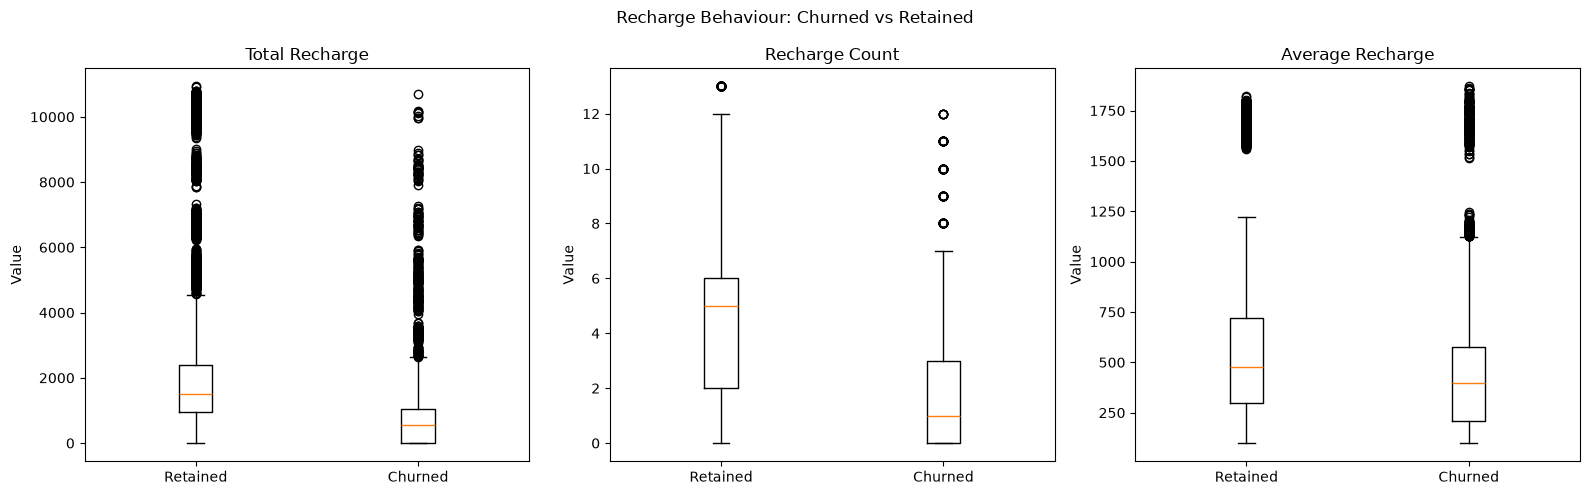

In [14]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

columns = [
    'total_recharge',
    'recharge_count',
    'average_recharge'
]

titles = [
    'Total Recharge',
    'Recharge Count',
    'Average Recharge'
]

for ax, column, title in zip(axes, columns, titles):

    ax.boxplot([
        retained[column].dropna(),
        churned[column].dropna()
    ])

    ax.set_xticklabels(['Retained', 'Churned'])
    ax.set_title(title)
    ax.set_ylabel('Value')

plt.suptitle('Recharge Behaviour: Churned vs Retained')
plt.tight_layout()
plt.show()


In [15]:

# Complete Task 1 statistical results

test_columns = {
    'T1 - Total Recharge': 'total_recharge',
    'T2 - Recharge Count': 'recharge_count',
    'T3 - Average Recharge': 'average_recharge'
}

results = []

for test_name, column in test_columns.items():

    # Average recharge includes only recharge-active subscribers
    if column == 'average_recharge':
        group_retained = retained.loc[
            retained['recharge_count'] > 0, column
        ].dropna()

        group_churned = churned.loc[
            churned['recharge_count'] > 0, column
        ].dropna()
    else:
        group_retained = retained[column].dropna()
        group_churned = churned[column].dropna()

    test = stats.ttest_ind(
        group_retained,
        group_churned,
        equal_var=False,
        alternative='two-sided'
    )

    results.append({
        'Test': test_name,
        'Retained_N': len(group_retained),
        'Churned_N': len(group_churned),
        'Retained_Mean': group_retained.mean(),
        'Churned_Mean': group_churned.mean(),
        'Retained_Median': group_retained.median(),
        'Churned_Median': group_churned.median(),
        'Retained_SD': group_retained.std(),
        'Churned_SD': group_churned.std(),
        'Difference_Churned_Retained':
            group_churned.mean() - group_retained.mean(),
        'T_Statistic': test.statistic,
        'P_Value': test.pvalue,
        'Decision': 'Reject H0' if test.pvalue < 0.05
                    else 'Fail to reject H0'
    })

task1_results = pd.DataFrame(results)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

display(task1_results.round(4))


,Test,Retained_N,Churned_N,Retained_Mean,Churned_Mean,Retained_Median,Churned_Median,Retained_SD,Churned_SD,Difference_Churned_Retained,T_Statistic,P_Value,Decision
0,T1 - Total Recharge,16774,5226,2421.5538,928.0758,1495.0,563.0,2644.7004,1391.8397,-1493.4781,53.2141,0.0,Reject H0
1,T2 - Recharge Count,16774,5226,4.3615,2.0155,5.0,1.0,2.7928,2.1337,-2.3460,64.1802,0.0,Reject H0
2,T3 - Average Recharge,14707,3582,593.6211,515.4687,479.0,399.0,430.9009,426.1192,-78.1524,9.8216,0.0,Reject H0


# Task 2 – Recharge Frequency and Churn Rate

### Cell 12 – Create frequency categories

In [16]:

# Create recharge frequency categories

validation_df['recharge_category'] = pd.cut(
    validation_df['recharge_count'],
    bins=[-1, 2, 5, float('inf')],
    labels=['Low', 'Medium', 'High']
)

print("Recharge categories created successfully!")

display(
    validation_df[
        ['customer_id', 'recharge_count', 'recharge_category', 'is_churned']
    ].head(10)
)


Recharge categories created successfully!


,customer_id,recharge_count,recharge_category,is_churned
0,9,5,Medium,0
1,31,2,Low,0
2,151,6,High,0
3,186,2,Low,0
4,207,2,Low,1
5,241,6,High,0
6,247,6,High,0
7,266,0,Low,1
8,274,1,Low,0
9,388,6,High,0


### Cell 13 – Frequency and churn summary

In [17]:

frequency_summary = validation_df.groupby(
    'recharge_category', observed=False
).agg(
    total_subscribers=('customer_id', 'count'),
    churned_subscribers=('is_churned', 'sum')
).reset_index()

frequency_summary['churn_percentage'] = (
    frequency_summary['churned_subscribers']
    / frequency_summary['total_subscribers']
) * 100

display(frequency_summary.round(2))


,recharge_category,total_subscribers,churned_subscribers,churn_percentage
0,Low,8812,3413,38.73
1,Medium,5147,1567,30.44
2,High,8041,246,3.06


### Cell 14 – Perform Z-test

In [18]:

# Select Low and High frequency groups

low_group = validation_df[
    validation_df['recharge_category'] == 'Low'
]

high_group = validation_df[
    validation_df['recharge_category'] == 'High'
]

# Count churned subscribers
low_churned = low_group['is_churned'].sum()
high_churned = high_group['is_churned'].sum()

# Total subscribers
low_total = len(low_group)
high_total = len(high_group)

# Calculate churn proportions
low_rate = low_churned / low_total
high_rate = high_churned / high_total

# Two-proportion Z-test
z_stat, p_value = proportions_ztest(
    count=[low_churned, high_churned],
    nobs=[low_total, high_total],
    alternative='two-sided'
)

print("LOW FREQUENCY")
print("Subscribers:", low_total)
print("Churned:", low_churned)
print("Churn Rate:", round(low_rate * 100, 2), "%")

print("\nHIGH FREQUENCY")
print("Subscribers:", high_total)
print("Churned:", high_churned)
print("Churn Rate:", round(high_rate * 100, 2), "%")

print("\nPercentage Point Difference (Low - High):",
      round((low_rate - high_rate) * 100, 2))

print("\nZ Statistic:", z_stat)
print("P Value:", p_value)

if p_value < 0.05:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")


LOW FREQUENCY
Subscribers: 8812
Churned: 3413
Churn Rate: 38.73 %

HIGH FREQUENCY
Subscribers: 8041
Churned: 246
Churn Rate: 3.06 %

Percentage Point Difference (Low - High): 35.67

Z Statistic: 56.10329223344183
P Value: 0.0
Decision: Reject H0


### Cell 15 – Churn rate chart

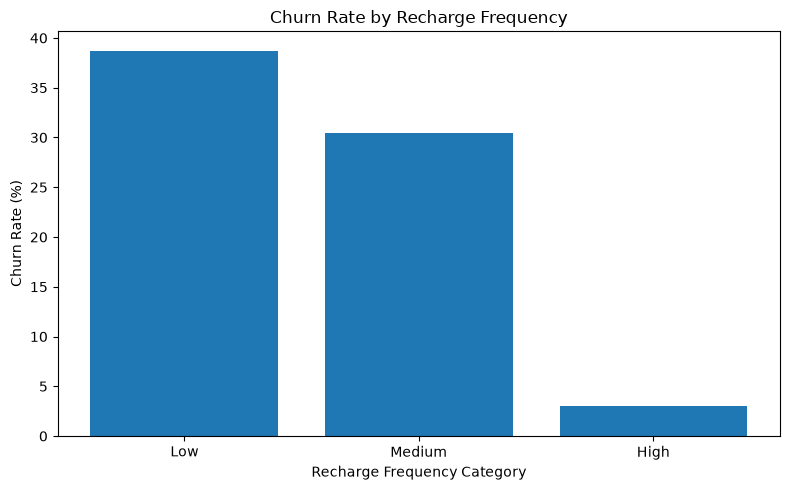

In [19]:

plt.figure(figsize=(8, 5))

plt.bar(
    frequency_summary['recharge_category'].astype(str),
    frequency_summary['churn_percentage']
)

plt.title('Churn Rate by Recharge Frequency')
plt.xlabel('Recharge Frequency Category')
plt.ylabel('Churn Rate (%)')

plt.tight_layout()
plt.show()


# Task 3 – Customer Tenure and Churn Status

### Cell 16 – Calculate tenure statistics

In [20]:

# Separate tenure data

retained_tenure = validation_df[
    validation_df['is_churned'] == 0
]['tenure_days'].dropna()

churned_tenure = validation_df[
    validation_df['is_churned'] == 1
]['tenure_days'].dropna()

# Descriptive statistics

tenure_summary = pd.DataFrame({
    'Group': ['Retained', 'Churned'],
    'Sample_Size': [
        len(retained_tenure),
        len(churned_tenure)
    ],
    'Mean_Tenure': [
        retained_tenure.mean(),
        churned_tenure.mean()
    ],
    'Median_Tenure': [
        retained_tenure.median(),
        churned_tenure.median()
    ],
    'Standard_Deviation': [
        retained_tenure.std(),
        churned_tenure.std()
    ]
})

display(tenure_summary.round(2))


,Group,Sample_Size,Mean_Tenure,Median_Tenure,Standard_Deviation
0,Retained,16774,711.88,720.0,331.75
1,Churned,5226,651.59,633.0,328.85


### Cell 17 – Perform Welch's t-test

In [21]:

# Two-tailed Welch's independent samples t-test

tenure_test = stats.ttest_ind(
    retained_tenure,
    churned_tenure,
    equal_var=False,
    alternative='two-sided'
)

print("TENURE STATISTICAL TEST")
print("------------------------------")

print("Mean Difference (Churned - Retained):",
      round(churned_tenure.mean() - retained_tenure.mean(), 2))

print("T-statistic:", tenure_test.statistic)
print("P-value:", tenure_test.pvalue)

if tenure_test.pvalue < 0.05:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")


TENURE STATISTICAL TEST
------------------------------
Mean Difference (Churned - Retained): -60.29
T-statistic: 11.54884292689635
P-value: 1.244091060345417e-30
Decision: Reject H0


### Cell 18 – Create tenure box plot

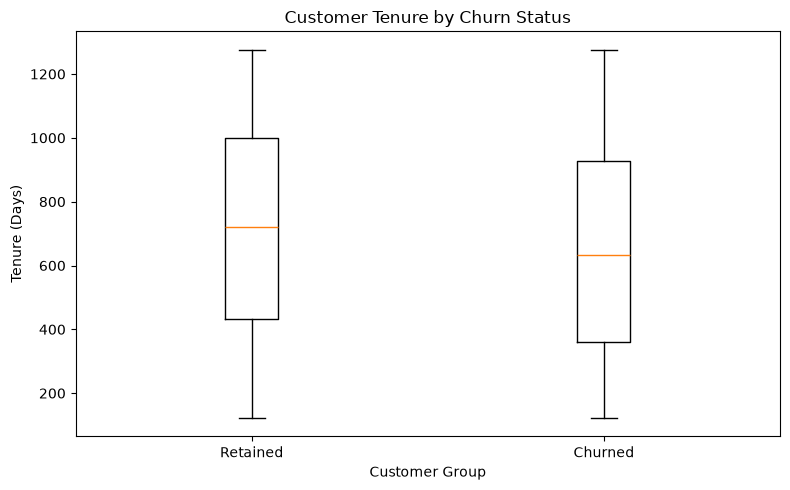

In [22]:

plt.figure(figsize=(8, 5))

plt.boxplot(
    [retained_tenure, churned_tenure],
    tick_labels=['Retained', 'Churned']
)

plt.title('Customer Tenure by Churn Status')
plt.xlabel('Customer Group')
plt.ylabel('Tenure (Days)')

plt.tight_layout()
plt.show()


# Task 4 – Robustness and Sensitivity Check

### Cell 19 – Create recharge-active dataset

In [23]:

# Full subscriber population
full_population = validation_df.copy()

# Recharge-active subscribers
active_population = validation_df[
    validation_df['recharge_count'] > 0
].copy()

print("FULL POPULATION:", len(full_population))
print("ACTIVE POPULATION:", len(active_population))

print("FULL POPULATION - CHURN STATUS")
display(full_population['is_churned'].value_counts())

print("\nACTIVE POPULATION - CHURN STATUS")
display(active_population['is_churned'].value_counts())


FULL POPULATION: 22000
ACTIVE POPULATION: 18289
FULL POPULATION - CHURN STATUS


is_churned
0    16774
1     5226
Name: count, dtype: int64


ACTIVE POPULATION - CHURN STATUS


is_churned
0    14707
1     3582
Name: count, dtype: int64

### Cell 20 – Perform robustness tests

In [24]:

# Function for comparing total recharge

def robustness_test(data, population_name):

    retained_data = data[data['is_churned'] == 0]['total_recharge']
    churned_data = data[data['is_churned'] == 1]['total_recharge']

    test = stats.ttest_ind(
        retained_data,
        churned_data,
        equal_var=False,
        alternative='two-sided'
    )

    return {
        'Population': population_name,
        'Retained_N': len(retained_data),
        'Churned_N': len(churned_data),
        'Retained_Mean': retained_data.mean(),
        'Churned_Mean': churned_data.mean(),
        'Difference': churned_data.mean() - retained_data.mean(),
        'T_Statistic': test.statistic,
        'P_Value': test.pvalue,
        'Decision': 'Reject H0' if test.pvalue < 0.05
                    else 'Fail to reject H0'
    }


# Compare both populations

robustness_results = pd.DataFrame([
    robustness_test(full_population, 'Full Population'),
    robustness_test(active_population, 'Recharge-Active Population')
])

display(robustness_results.round(4))


,Population,Retained_N,Churned_N,Retained_Mean,Churned_Mean,Difference,T_Statistic,P_Value,Decision
0,Full Population,16774,5226,2421.5538,928.0758,-1493.4781,53.2141,0.0,Reject H0
1,Recharge-Active Population,14707,3582,2761.8919,1354.0268,-1407.8651,42.3227,0.0,Reject H0


### Cell 21 – Visual comparison

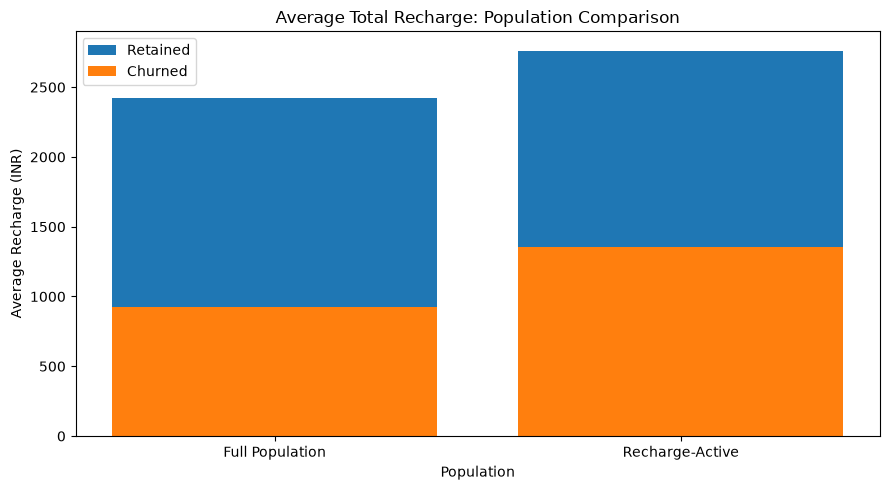

In [25]:

plt.figure(figsize=(9, 5))

plt.bar(
    ['Full Population', 'Recharge-Active'],
    robustness_results['Retained_Mean'],
    label='Retained'
)

plt.bar(
    ['Full Population', 'Recharge-Active'],
    robustness_results['Churned_Mean'],
    label='Churned'
)

plt.title('Average Total Recharge: Population Comparison')
plt.xlabel('Population')
plt.ylabel('Average Recharge (INR)')
plt.legend()

plt.tight_layout()
plt.show()


## Cell 22 – Create consolidated results table

In [26]:

# Consolidated statistical results

summary_rows = []

# Task 1: Three Welch t-tests
for _, row in task1_results.iterrows():

    summary_rows.append({
        'Test ID': row['Test'],
        'Research Question': 'Does recharge behaviour differ by churn status?',
        'Group 1': 'Retained',
        'Group 2': 'Churned',
        'Sample Size 1': row['Retained_N'],
        'Sample Size 2': row['Churned_N'],
        'Group Values': (
            f"Mean: {row['Retained_Mean']:.2f} vs "
            f"{row['Churned_Mean']:.2f}"
        ),
        'Difference': row['Difference_Churned_Retained'],
        'Test Used': "Welch's independent t-test",
        'Test Statistic': row['T_Statistic'],
        'p-value': row['P_Value'],
        'Significance Level': 0.05,
        'Decision': row['Decision'],
        'Business Interpretation': (
            'Recharge behaviour differs significantly between the groups.'
            if row['P_Value'] < 0.05
            else 'Insufficient evidence of a group difference.'
        )
    })

# Task 2: Two-proportion Z-test
summary_rows.append({
    'Test ID': 'T4 - Recharge Frequency',
    'Research Question': 'Does churn proportion differ between low and high frequency?',
    'Group 1': 'Low frequency',
    'Group 2': 'High frequency',
    'Sample Size 1': low_total,
    'Sample Size 2': high_total,
    'Group Values': f"{low_rate*100:.2f}% vs {high_rate*100:.2f}%",
    'Difference': (low_rate - high_rate) * 100,
    'Test Used': 'Two-proportion Z-test',
    'Test Statistic': z_stat,
    'p-value': p_value,
    'Significance Level': 0.05,
    'Decision': 'Reject H0' if p_value < 0.05 else 'Fail to reject H0',
    'Business Interpretation': 'Churn proportions differ significantly.'
        if p_value < 0.05 else 'Insufficient evidence of a difference.'
})

# Task 3: Tenure comparison
summary_rows.append({
    'Test ID': 'T5 - Customer Tenure',
    'Research Question': 'Does customer tenure differ by churn status?',
    'Group 1': 'Retained',
    'Group 2': 'Churned',
    'Sample Size 1': len(retained_tenure),
    'Sample Size 2': len(churned_tenure),
    'Group Values': (
        f"Mean: {retained_tenure.mean():.2f} vs "
        f"{churned_tenure.mean():.2f} days"
    ),
    'Difference': churned_tenure.mean() - retained_tenure.mean(),
    'Test Used': "Welch's independent t-test",
    'Test Statistic': tenure_test.statistic,
    'p-value': tenure_test.pvalue,
    'Significance Level': 0.05,
    'Decision': 'Reject H0' if tenure_test.pvalue < 0.05
                else 'Fail to reject H0',
    'Business Interpretation': 'Customer tenure differs significantly.'
        if tenure_test.pvalue < 0.05
        else 'Insufficient evidence of a tenure difference.'
})

# Task 4: Robustness comparisons
for _, row in robustness_results.iterrows():

    summary_rows.append({
        'Test ID': 'T6 - ' + row['Population'],
        'Research Question': 'Does total recharge differ by churn status?',
        'Group 1': 'Retained',
        'Group 2': 'Churned',
        'Sample Size 1': row['Retained_N'],
        'Sample Size 2': row['Churned_N'],
        'Group Values': (
            f"Mean: {row['Retained_Mean']:.2f} vs "
            f"{row['Churned_Mean']:.2f}"
        ),
        'Difference': row['Difference'],
        'Test Used': "Welch's independent t-test",
        'Test Statistic': row['T_Statistic'],
        'p-value': row['P_Value'],
        'Significance Level': 0.05,
        'Decision': row['Decision'],
        'Business Interpretation': 'Recharge difference is statistically significant.'
            if row['P_Value'] < 0.05
            else 'Insufficient evidence of a difference.'
    })

# Create DataFrame
final_results = pd.DataFrame(summary_rows)

display(final_results.round(4))


,Test ID,Research Question,Group 1,Group 2,Sample Size 1,Sample Size 2,Group Values,Difference,Test Used,Test Statistic,p-value,Significance Level,Decision,Business Interpretation
0,T1 - Total Recharge,Does recharge behaviour differ by churn status?,Retained,Churned,16774,5226,Mean: 2421.55 vs 928.08,-1493.4781,Welch's independent t-test,53.2141,0.0,0.05,Reject H0,Recharge behaviour differs significantly betwe...
1,T2 - Recharge Count,Does recharge behaviour differ by churn status?,Retained,Churned,16774,5226,Mean: 4.36 vs 2.02,-2.3460,Welch's independent t-test,64.1802,0.0,0.05,Reject H0,Recharge behaviour differs significantly betwe...
2,T3 - Average Recharge,Does recharge behaviour differ by churn status?,Retained,Churned,14707,3582,Mean: 593.62 vs 515.47,-78.1524,Welch's independent t-test,9.8216,0.0,0.05,Reject H0,Recharge behaviour differs significantly betwe...
3,T4 - Recharge Frequency,Does churn proportion differ between low and h...,Low frequency,High frequency,8812,8041,38.73% vs 3.06%,35.6720,Two-proportion Z-test,56.1033,0.0,0.05,Reject H0,Churn proportions differ significantly.
4,T5 - Customer Tenure,Does customer tenure differ by churn status?,Retained,Churned,16774,5226,Mean: 711.88 vs 651.59 days,-60.2922,Welch's independent t-test,11.5488,0.0,0.05,Reject H0,Customer tenure differs significantly.
5,T6 - Full Population,Does total recharge differ by churn status?,Retained,Churned,16774,5226,Mean: 2421.55 vs 928.08,-1493.4781,Welch's independent t-test,53.2141,0.0,0.05,Reject H0,Recharge difference is statistically significant.
6,T6 - Recharge-Active Population,Does total recharge differ by churn status?,Retained,Churned,14707,3582,Mean: 2761.89 vs 1354.03,-1407.8651,Welch's independent t-test,42.3227,0.0,0.05,Reject H0,Recharge difference is statistically significant.


## Cell 23 – Export Excel workbook

In [27]:

import os

# Create reports folder if it does not exist
os.makedirs('../reports', exist_ok=True)

# Export statistical summary
excel_path = '../reports/07_Validation_Summary.xlsx'

final_results.to_excel(
    excel_path,
    index=False,
    sheet_name='Statistical Summary'
)

print("Excel summary saved successfully!")
print("File location:", excel_path)


Excel summary saved successfully!
File location: ../reports/07_Validation_Summary.xlsx
